In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/clustering/D4/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
df_scm = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_scm.csv')
df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with KiralyMSMApproximateClustering,2663,0.20,cosine,98.63,97.34,97.98,2155,30,2575,59,cosine,[title],1024,0,1,salted_qgrams,,4
1,Clustering with KiralyMSMApproximateClustering,2663,0.30,cosine,98.63,97.34,97.98,2155,30,2575,59,cosine,[title],1024,0,1,salted_qgrams,,4
2,Clustering with KiralyMSMApproximateClustering,2666,0.40,cosine,98.76,97.34,98.04,2155,27,2575,59,cosine,[title],1024,0,1,salted_qgrams,,4
3,Clustering with KiralyMSMApproximateClustering,2667,0.50,cosine,98.81,97.34,98.07,2155,26,2575,59,cosine,[title],1024,0,1,salted_qgrams,,4
4,Clustering with KiralyMSMApproximateClustering,2673,0.60,cosine,98.94,97.20,98.06,2152,23,2572,62,cosine,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2427,Clustering with KiralyMSMApproximateClustering,2029,0.55,scm,97.63,89.48,93.38,1981,48,2401,233,scm,[title],1024,0,32,salted_qgrams,,4
2428,Clustering with KiralyMSMApproximateClustering,2136,0.65,scm,98.31,94.85,96.55,2100,36,2520,114,scm,[title],1024,0,32,salted_qgrams,,4
2429,Clustering with KiralyMSMApproximateClustering,2166,0.75,scm,98.75,96.61,97.67,2139,27,2559,75,scm,[title],1024,0,32,salted_qgrams,,4
2430,Clustering with KiralyMSMApproximateClustering,2159,0.85,scm,99.03,96.57,97.78,2138,21,2558,76,scm,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    2432
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    2432
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    2432
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    2432
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    2432
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     76
2     76
3     76
4     76
5     76
6     76
7     76
8     76
9     76
10    76
11    76
12    76
13    76
14    76
15    76
16    76
17    76
18    76
19    76
20    76
21    76
22    76
23    76
24    76
25    76
26    76
27    76
28    76
29    76
30    76
31    76
32    76
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
3,Clustering with KiralyMSMApproximateClustering,2667,0.5,cosine,98.81,97.34,98.07,2155,26,2575,59,cosine,[title],1024,0,1,salted_qgrams,,4
610,Clustering with KiralyMSMApproximateClustering,2674,0.6,dice,98.99,97.20,98.09,2152,22,2572,62,dice,[title],1024,0,1,salted_qgrams,,4
1219,Clustering with KiralyMSMApproximateClustering,2674,0.4,jaccard,98.99,97.20,98.09,2152,22,2572,62,jaccard,[title],1024,0,1,salted_qgrams,,4
1824,Clustering with KiralyMSMApproximateClustering,2667,0.1,scm,98.44,96.97,97.70,2147,34,2567,67,scm,[title],1024,0,1,salted_qgrams,,4
12,Clustering with KiralyMSMApproximateClustering,2666,0.5,cosine,98.81,97.38,98.09,2156,26,2576,58,cosine,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,Clustering with KiralyMSMApproximateClustering,2671,0.7,scm,98.71,97.06,97.88,2149,28,2569,65,scm,[title],1024,0,31,salted_qgrams,,4
281,Clustering with KiralyMSMApproximateClustering,2674,0.7,cosine,98.90,97.11,97.99,2150,24,2570,64,cosine,[title],1024,0,32,salted_qgrams,,4
890,Clustering with KiralyMSMApproximateClustering,2673,0.6,dice,98.80,97.06,97.93,2149,26,2569,65,dice,[title],1024,0,32,salted_qgrams,,4
1499,Clustering with KiralyMSMApproximateClustering,2674,0.5,jaccard,98.85,97.06,97.95,2149,25,2569,65,jaccard,[title],1024,0,32,salted_qgrams,,4


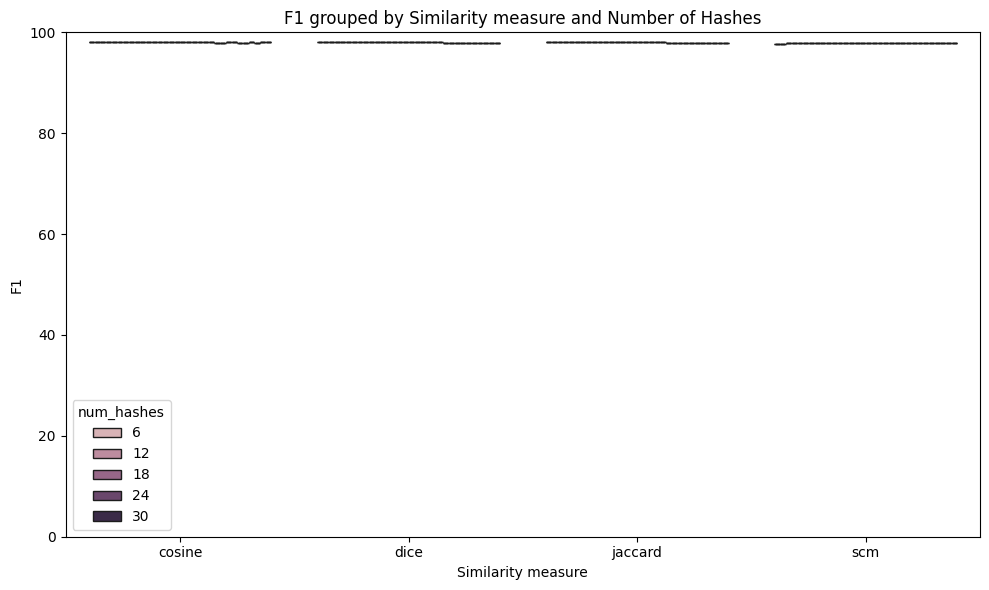

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,98.81
1,dice,1,Precision %,98.99
2,jaccard,1,Precision %,98.99
3,scm,1,Precision %,98.44
4,cosine,2,Precision %,98.81
...,...,...,...,...
379,scm,31,F1 %,97.88
380,cosine,32,F1 %,97.99
381,dice,32,F1 %,97.93
382,jaccard,32,F1 %,97.95


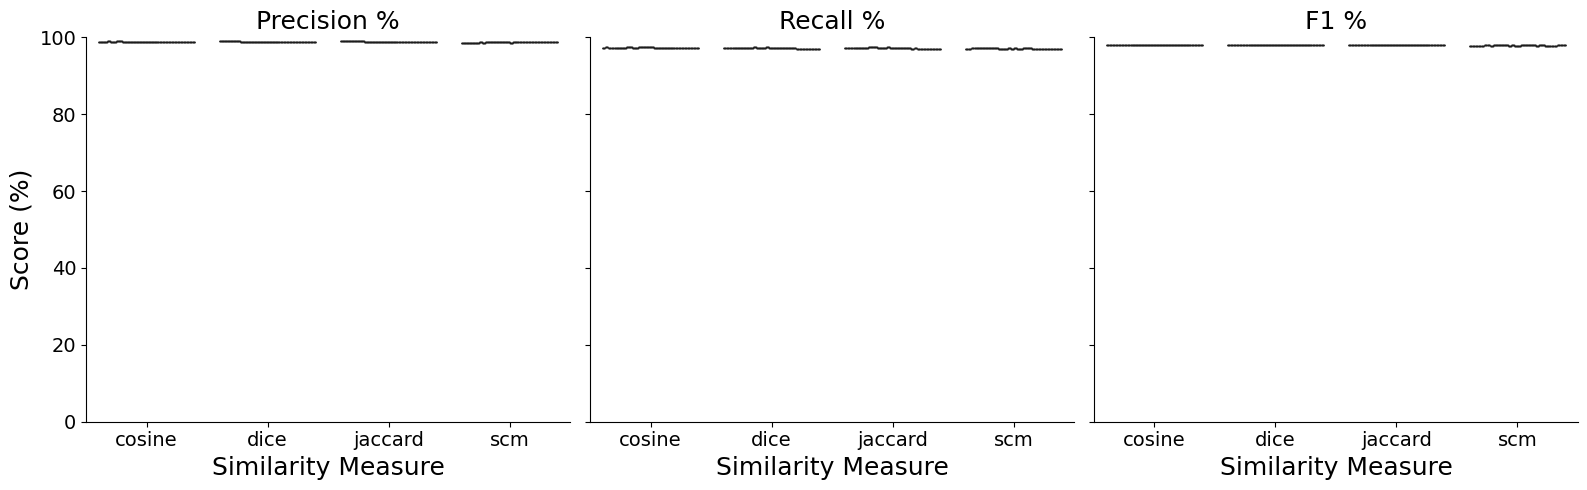

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

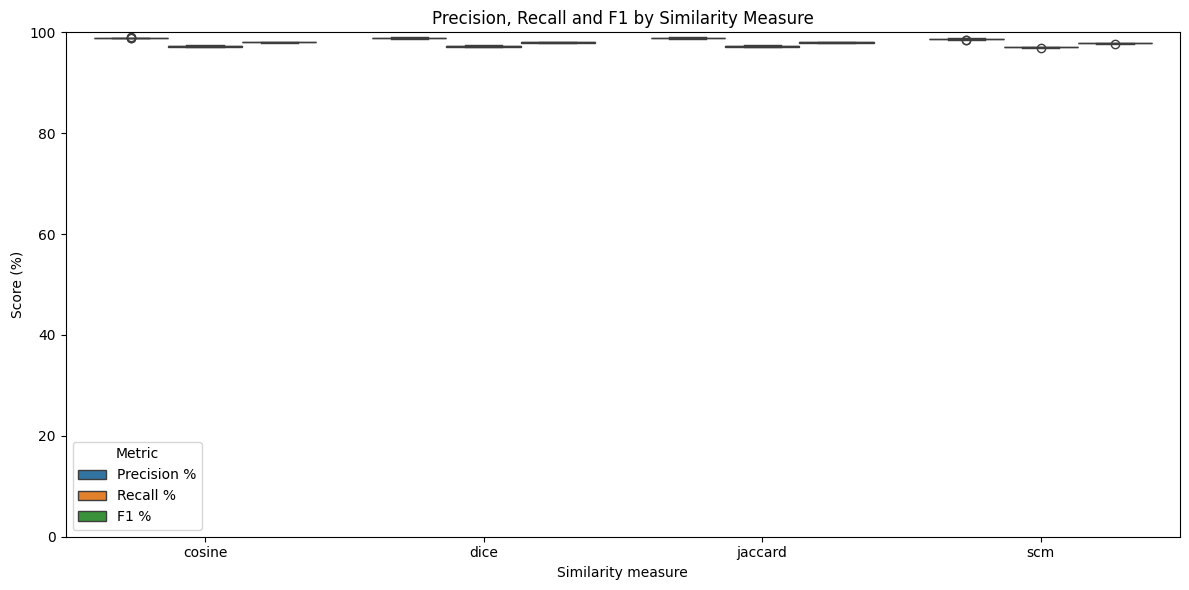

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()